# Phase 3 — Bayesian Monte Carlo: simulate with an uncertain edge

**Purpose.** Phase 1 simulated futures with one fixed edge (23% win rate,
8R winner). Phase 2 showed that the true edge is not one number; it is a
range. This notebook joins the two: **every simulated future draws its own
plausible edge** from the Phase 2 belief, then trades with it.

**Mission.** Answer three questions:

1. How does the picture change when the edge is uncertain?
2. What is the chance that the account ends below where it started?
3. What risk per trade is the largest that stays inside a drawdown limit?

**The linear algebra.** Each future has its own win rate. That is a column
vector of shape (paths, 1). The random numbers are a matrix of shape
(paths, trades). Comparing the two stretches the column across every trade.
This is **broadcasting**, and it replaces a loop over 10,000 futures.

**Read this first.** The default trade log is `sample_trade_log.csv`:
40 **made-up** trades. Results below describe that made-up trader. Point
`TRADE_LOG` at your own file for your own answer. Study tool, not advice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

import lab_style as ls
import mc_engine as mc
import bayes_edge as be

ls.use_lab_style()
dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")

In [2]:
# ============================================================
# KEY IN HERE
# ============================================================
TRADE_LOG    = "sample_trade_log.csv"   # same file as Phase 2
START_EQUITY = 2000
RISK_PCT     = 0.01      # risk per trade to examine first
TRADES       = 300
PATHS        = 10_000
SEED         = 42

DRAWDOWN_LIMIT = 0.30    # a drawdown you do not want to live through
MAX_CHANCE     = 0.10    # largest acceptable chance of hitting that drawdown

prior = be.Prior()       # borrowed 23% and 8R, held loosely (see Phase 2)

## Step 1 — The belief about the edge (from Phase 2)

20,000 draws. Each draw is one plausible trader: a win rate, an average
winner, a winner spread and an average loser.

In [3]:
log = be.load_trade_log(TRADE_LOG)
edge = be.sample_edge(log["R"].to_numpy(), prior, draws=20_000, seed=0)
p_positive = float(np.mean(edge["expectancy_R"] > 0))

print(f"Trades in log: {len(log)}")
print(f"P(edge > 0) = {p_positive:.0%}")
edge.describe(percentiles=[0.05, 0.5, 0.95]).T[["5%", "50%", "95%"]].round(2)

Trades in log: 40
P(edge > 0) = 62%


,5%,50%,95%
win_rate,0.13,0.21,0.30
avg_win_R,2.89,4.23,7.22
win_sigma,0.62,0.82,1.16
avg_loss_R,0.98,0.98,0.98
expectancy_R,-0.36,0.11,0.98


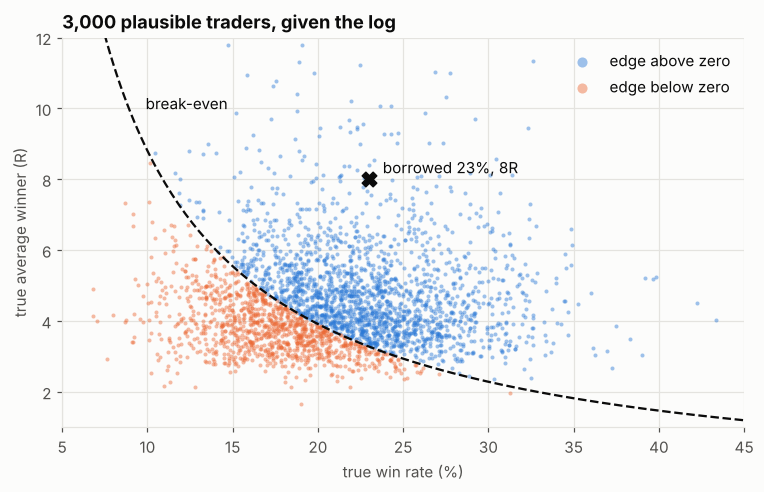

In [4]:
# Each dot is one plausible trader. The curve is break-even:
# win rate x average winner = loss rate x average loser.
show = edge.sample(3000, random_state=0)
positive = show["expectancy_R"] > 0
avg_loss = edge["avg_loss_R"].iloc[0]
wr = np.linspace(0.05, 0.45, 200)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(100 * show.loc[positive, "win_rate"], show.loc[positive, "avg_win_R"],
           s=7, color=ls.BLUE, alpha=0.45, linewidths=0, label="edge above zero")
ax.scatter(100 * show.loc[~positive, "win_rate"], show.loc[~positive, "avg_win_R"],
           s=7, color=ls.ORANGE, alpha=0.45, linewidths=0, label="edge below zero")
ax.plot(100 * wr, (1 - wr) * avg_loss / wr, color=ls.TEXT, lw=1.5, ls="--")
ax.annotate("break-even", (9, (1 - 0.09) * avg_loss / 0.09),
            textcoords="offset points", xytext=(10, 2), color=ls.TEXT)
ax.scatter([23], [8], s=90, marker="X", color=ls.TEXT, zorder=4)
ax.annotate("borrowed 23%, 8R", (23, 8), textcoords="offset points",
            xytext=(9, 4), color=ls.TEXT)
ax.set_xlim(5, 45); ax.set_ylim(1, 12)
ax.set_xlabel("true win rate (%)"); ax.set_ylabel("true average winner (R)")
ax.set_title("3,000 plausible traders, given the log")
ax.legend(loc="upper right", markerscale=2.5)
plt.show()

## Step 2 — Broadcasting: one edge per future

A small example first. Three futures, five trades. Each future has its own
win rate, held in a column of shape (3, 1).

In [5]:
rng = np.random.default_rng(1)
win_rate_column = np.array([[0.10], [0.25], [0.60]])       # shape (3, 1)
random_matrix = rng.random((3, 5))                          # shape (3, 5)
is_win = random_matrix < win_rate_column                    # shape (3, 5)

print("win-rate column shape:", win_rate_column.shape)
print("random matrix shape  :", random_matrix.shape)
print("result shape         :", is_win.shape)
print("\nwins in each future (True = win):")
print(is_win)

win-rate column shape: (3, 1)
random matrix shape  : (3, 5)
result shape         : (3, 5)

wins in each future (True = win):
[[False False False False False]
 [False False False False  True]
 [False  True  True False  True]]


Row 1 used 10%, row 2 used 25%, row 3 used 60%, with no loop. The engine
function `simulate_R_uncertain` does the same for 10,000 futures.

## Step 3 — Three ways to simulate

| Run | Edge used by each future |
|---|---|
| A. Borrowed | 23% win rate, 8R winner, fixed (Phase 1) |
| B. Plug-in | the median of your belief, fixed |
| C. Uncertain | its own draw from your belief |

Run B is what most people do: take the best estimate and treat it as true.
Run C is the honest one.

In [6]:
mid = edge.median()
rules_A = mc.Rules(start_equity=START_EQUITY, risk_pct=RISK_PCT)
rules_B = mc.Rules(start_equity=START_EQUITY, risk_pct=RISK_PCT,
                   win_rate=mid["win_rate"], avg_win_R=mid["avg_win_R"],
                   win_sigma=mid["win_sigma"])

R_A = mc.simulate_R(rules_A, PATHS, TRADES, np.random.default_rng(SEED))
R_B = mc.simulate_R(rules_B, PATHS, TRADES, np.random.default_rng(SEED)) * 1.0
R_B = np.where(R_B < 0, -mid["avg_loss_R"], R_B)
R_C, row = mc.simulate_R_uncertain(edge, PATHS, TRADES, np.random.default_rng(SEED))

runs = {"A. Borrowed edge": R_A, "B. Plug-in median": R_B, "C. Uncertain edge": R_C}
equity = {name: mc.equity_paths(R, START_EQUITY, RISK_PCT) for name, R in runs.items()}

for name, R in runs.items():
    print(f"{name:20s} mean result {R.mean():+.2f} R per trade")

A. Borrowed edge     mean result +1.07 R per trade
B. Plug-in median    mean result +0.10 R per trade
C. Uncertain edge    mean result +0.19 R per trade


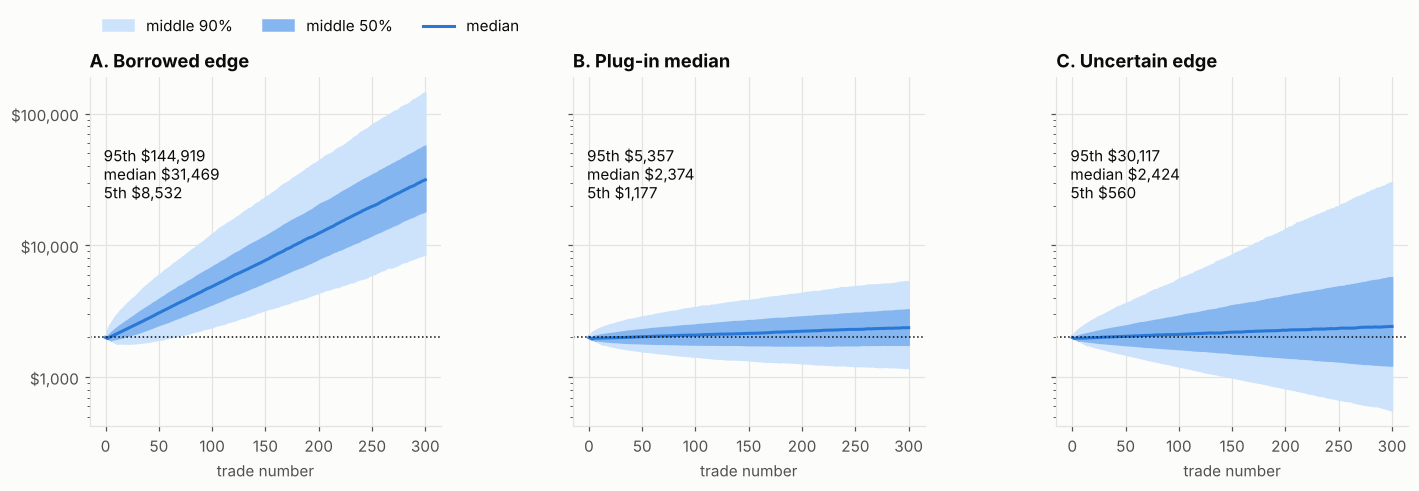

In [7]:
x = np.arange(TRADES + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for ax, (name, eq) in zip(axes, equity.items()):
    p5, p25, p50, p75, p95 = np.percentile(eq, [5, 25, 50, 75, 95], axis=0)
    ax.fill_between(x, p5, p95, color=ls.BLUE_BAND_OUTER, label="middle 90%")
    ax.fill_between(x, p25, p75, color=ls.BLUE_BAND_INNER, label="middle 50%")
    ax.plot(x, p50, color=ls.BLUE, label="median")
    ax.axhline(START_EQUITY, color=ls.TEXT, lw=1, ls=":")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(dollars)
    ax.set_title(name); ax.set_xlabel("trade number")
    ax.annotate(f"95th ${p95[-1]:,.0f}\nmedian ${p50[-1]:,.0f}\n5th ${p5[-1]:,.0f}",
                (0.04, 0.80), xycoords="axes fraction", color=ls.TEXT, va="top")
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=3)
plt.tight_layout(); plt.show()

In [8]:
summary = pd.DataFrame({name: mc.summarize(equity[name], runs[name]) for name in runs}).T
keep = ["Final equity, 5th pct ($)", "Final equity, median ($)",
        "Final equity, 95th pct ($)", "P(end below start) %",
        "Max drawdown, median %", "P(drawdown >= 30%) %"]
print(summary[keep].round(0).astype(int).to_string())

                   Final equity, 5th pct ($)  Final equity, median ($)  Final equity, 95th pct ($)  P(end below start) %  Max drawdown, median %  P(drawdown >= 30%) %
A. Borrowed edge                        8532                     31469                      144919                     0                      20                     7
B. Plug-in median                       1177                      2374                        5357                    35                      33                    61
C. Uncertain edge                        560                      2424                       30117                    43                      33                    56


Runs B and C share the same median edge, and they tell different stories.
B says where the account goes **if the estimate is exactly right**. C keeps
the futures where the true edge is worse (or better) than the estimate, so
its fan is far wider and its lower band falls below the start.

## Step 4 — Why the fan is wide: good-edge and bad-edge futures

In run C each future knows the true expectancy it drew. Split the futures
by the sign of that true edge.

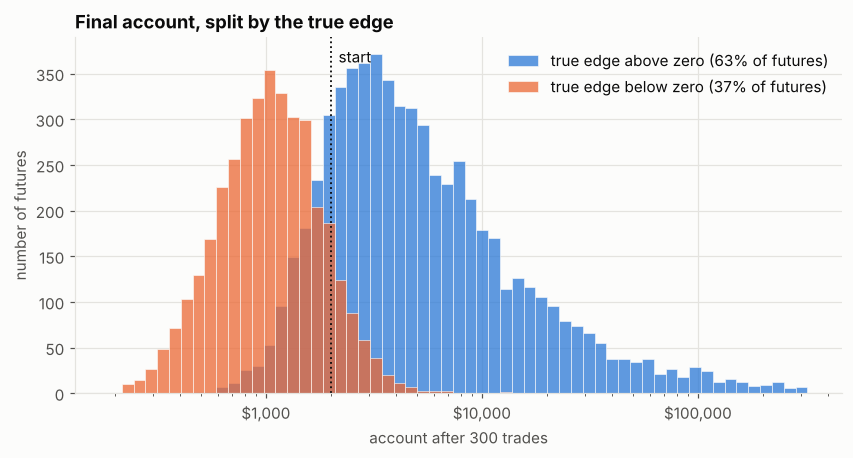

Futures with a true edge above zero: median final $4,387, 16% end below the start
Futures with a true edge below zero: median final $1,038, 89% end below the start


In [9]:
true_edge = edge["expectancy_R"].to_numpy()[row]
final_C = equity["C. Uncertain edge"][:, -1]
good, bad = true_edge > 0, true_edge <= 0

fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.logspace(np.log10(final_C.min()), np.log10(np.percentile(final_C, 99.5)), 60)
ax.hist(final_C[good], bins=bins, color=ls.BLUE, alpha=0.75, edgecolor=ls.SURFACE,
        linewidth=0.5, label=f"true edge above zero ({good.mean():.0%} of futures)")
ax.hist(final_C[bad], bins=bins, color=ls.ORANGE, alpha=0.75, edgecolor=ls.SURFACE,
        linewidth=0.5, label=f"true edge below zero ({bad.mean():.0%} of futures)")
ax.axvline(START_EQUITY, color=ls.TEXT, lw=1.2, ls=":")
ax.annotate("start", (START_EQUITY, ax.get_ylim()[1] * 0.93),
            textcoords="offset points", xytext=(5, 0), color=ls.TEXT)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel(f"account after {TRADES} trades"); ax.set_ylabel("number of futures")
ax.set_title("Final account, split by the true edge")
ax.legend(loc="upper right")
plt.show()

print(f"Futures with a true edge above zero: median final ${np.median(final_C[good]):,.0f}, "
      f"{100 * np.mean(final_C[good] < START_EQUITY):.0f}% end below the start")
print(f"Futures with a true edge below zero: median final ${np.median(final_C[bad]):,.0f}, "
      f"{100 * np.mean(final_C[bad] < START_EQUITY):.0f}% end below the start")

You cannot know in advance which group you are in. The sizing has to be
safe for both.

## Step 5 — Choose the risk per trade

The same 10,000 uncertain-edge futures, replayed at different risk settings.
Left: where the account ends. Right: the chance of the drawdown you set as
your limit, against the largest chance you accept.

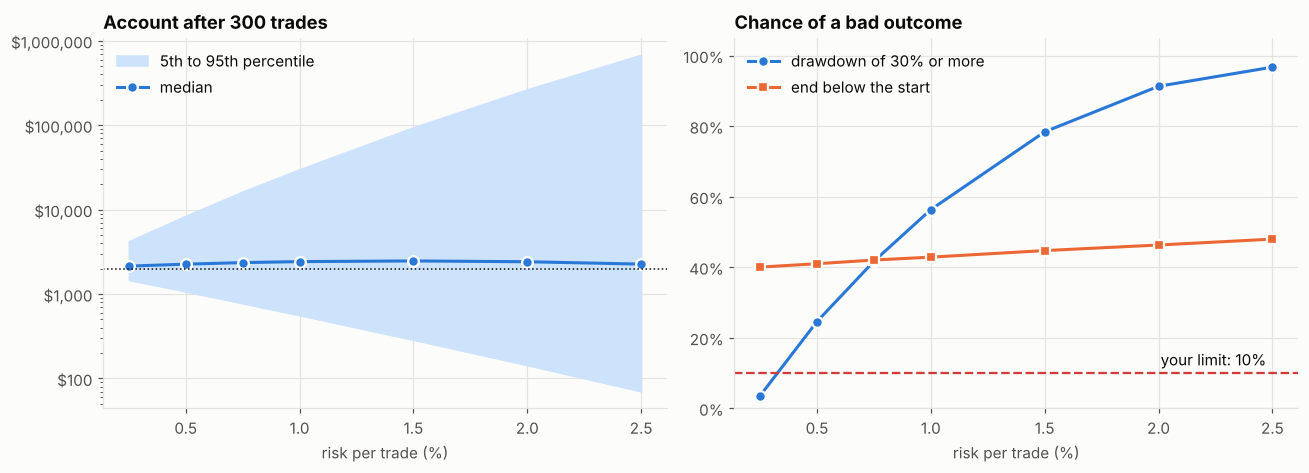

        5th pct ($)  median ($)  95th pct ($)  P(end below start) %  P(drawdown >= 30%) %
risk %                                                                                   
0.25           1467        2143          4225                    40                     4
0.50           1070        2261          8474                    41                    25
0.75            776        2358         16376                    42                    42
1.00            560        2424         30117                    43                    56
1.50            287        2468         94729                    45                    78
2.00            144        2416        266703                    46                    91
2.50             70        2264        683620                    48                    97


In [10]:
risk_grid = np.array([0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.025])
sweep = []
for rp in risk_grid:
    eq = mc.equity_paths(R_C, START_EQUITY, rp)
    final, dd = eq[:, -1], mc.max_drawdown(eq)
    sweep.append({"risk %": 100 * rp,
                  "5th pct ($)": np.percentile(final, 5),
                  "median ($)": np.median(final),
                  "95th pct ($)": np.percentile(final, 95),
                  "P(end below start) %": 100 * np.mean(final < START_EQUITY),
                  f"P(drawdown >= {DRAWDOWN_LIMIT:.0%}) %": 100 * np.mean(dd >= DRAWDOWN_LIMIT)})
sweep = pd.DataFrame(sweep).set_index("risk %")
dd_col = sweep.columns[-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.fill_between(sweep.index, sweep["5th pct ($)"], sweep["95th pct ($)"],
                color=ls.BLUE_BAND_OUTER, label="5th to 95th percentile")
ax.plot(sweep.index, sweep["median ($)"], color=ls.BLUE, marker="o", markersize=7,
        markeredgecolor=ls.SURFACE, markeredgewidth=1.5, label="median")
ax.axhline(START_EQUITY, color=ls.TEXT, lw=1, ls=":")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("risk per trade (%)"); ax.set_title(f"Account after {TRADES} trades")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(sweep.index, sweep[dd_col], color=ls.BLUE, marker="o", markersize=7,
        markeredgecolor=ls.SURFACE, markeredgewidth=1.5,
        label=f"drawdown of {DRAWDOWN_LIMIT:.0%} or more")
ax.plot(sweep.index, sweep["P(end below start) %"], color=ls.ORANGE, marker="s",
        markersize=7, markeredgecolor=ls.SURFACE, markeredgewidth=1.5,
        label="end below the start")
ax.axhline(100 * MAX_CHANCE, color=ls.CRITICAL, lw=1.5, ls="--")
ax.annotate(f"your limit: {MAX_CHANCE:.0%}", (sweep.index[-1], 100 * MAX_CHANCE),
            textcoords="offset points", xytext=(-4, 5), ha="right", color=ls.TEXT)
ax.set_ylim(0, 105); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xlabel("risk per trade (%)"); ax.set_title("Chance of a bad outcome")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

print(sweep.round(0).astype(int).to_string())

Two things to read. First, the median barely moves with risk, while the
5th percentile collapses: more risk mostly buys a wider range. Second, the
chance of ending below the start hardly depends on risk. It depends on
whether the edge is real, and sizing cannot fix a missing edge.

## Step 6 — Growth rate: uncertainty lowers the best bet size

The long-run growth rate of an account is the average of
`log(1 + R × risk)` over trades. The risk that maximises it is the Kelly
fraction. Compare the curve for the borrowed edge with the curve for the
uncertain edge.

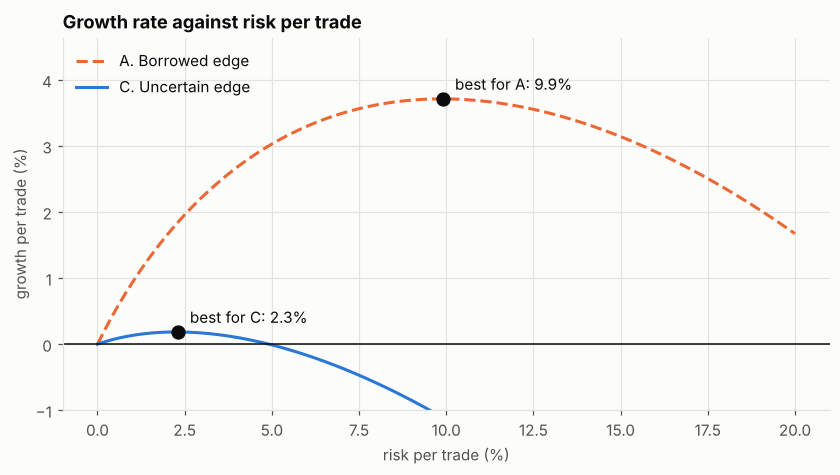

Growth-maximising risk, borrowed edge : 9.9%
Growth-maximising risk, uncertain edge: 2.3%
These are upper limits, not targets. At the growth-maximising risk the
drawdowns are severe; practitioners use a fraction of it.


In [11]:
fine_grid = np.linspace(0.0, 0.20, 201)

def growth_curve(R):
    """Average log growth per trade, in percent, at each risk setting."""
    out = []
    for rp in fine_grid:
        step = 1.0 + R * rp
        out.append(100 * np.mean(np.log(np.clip(step, 1e-9, None))))
    return np.array(out)

g_A, g_C = growth_curve(R_A), growth_curve(R_C)
best_A, best_C = fine_grid[g_A.argmax()], fine_grid[g_C.argmax()]

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(100 * fine_grid, g_A, color=ls.ORANGE, ls="--", label="A. Borrowed edge")
ax.plot(100 * fine_grid, g_C, color=ls.BLUE, label="C. Uncertain edge")
ax.axhline(0, color=ls.TEXT, lw=1)
for best, g, name in [(best_A, g_A, "A"), (best_C, g_C, "C")]:
    ax.scatter([100 * best], [g.max()], s=70, color=ls.TEXT, zorder=4)
    ax.annotate(f"best for {name}: {best:.1%}", (100 * best, g.max()),
                textcoords="offset points", xytext=(8, 6), color=ls.TEXT)
ax.set_ylim(-1.0, g_A.max() * 1.25)
ax.set_xlabel("risk per trade (%)"); ax.set_ylabel("growth per trade (%)")
ax.set_title("Growth rate against risk per trade")
ax.legend(loc="upper left")
plt.show()

print(f"Growth-maximising risk, borrowed edge : {best_A:.1%}")
print(f"Growth-maximising risk, uncertain edge: {best_C:.1%}")
print("These are upper limits, not targets. At the growth-maximising risk the")
print("drawdowns are severe; practitioners use a fraction of it.")

## Step 7 — The decision

Three limits, and the smallest one wins:

1. **Drawdown limit:** the largest risk whose chance of your drawdown limit
   stays within your accepted chance.
2. **Evidence limit:** the Phase 2 rule (0.5R until the edge is supported).
3. **Your rule:** 1R = 1% of equity.

In [12]:
fine_risk = np.arange(0.001, 0.0251, 0.001)
chance = np.array([np.mean(mc.max_drawdown(mc.equity_paths(R_C, START_EQUITY, rp))
                           >= DRAWDOWN_LIMIT) for rp in fine_risk])
allowed = fine_risk[chance <= MAX_CHANCE]
drawdown_limit_risk = allowed.max() if len(allowed) else 0.0

setting, reason = be.sizing_decision(p_positive, len(log))
evidence_risk = {"1R": 0.01, "0.5R": 0.005, "pause": 0.0}[setting]
final_risk = min(drawdown_limit_risk, evidence_risk, 0.01)

print(f"1. Drawdown limit : {drawdown_limit_risk:.1%} per trade "
      f"(P(drawdown >= {DRAWDOWN_LIMIT:.0%}) <= {MAX_CHANCE:.0%})")
print(f"2. Evidence limit : {evidence_risk:.1%} per trade  ({reason})")
print(f"3. Your rule      : 1.0% per trade")
print(f"\nRISK PER TRADE SUPPORTED BY THE EVIDENCE: {final_risk:.1%} "
      f"(${START_EQUITY * final_risk:,.0f} on ${START_EQUITY:,})")

1. Drawdown limit : 0.3% per trade (P(drawdown >= 30%) <= 10%)
2. Evidence limit : 0.5% per trade  (P(edge > 0) = 62%, between 60% and 90%. Stay at half risk.)
3. Your rule      : 1.0% per trade

RISK PER TRADE SUPPORTED BY THE EVIDENCE: 0.3% ($6 on $2,000)


## What this notebook shows

The figures below are for the **made-up sample log** (40 trades), 1% risk,
300 trades, 10,000 futures, seed 42. Your own log will give different numbers.

1. **The borrowed edge flatters.** With the borrowed edge the median future
   ends near \$31,500. With the edge the sample log supports, the median
   ends near \$2,400.
2. **A best estimate is not enough.** Runs B and C share one median edge.
   B says 35% of futures end below the start; C says 43%. C's 5th percentile
   is \$560 against B's \$1,177, and its 95th is \$30,117 against \$5,357.
3. **The split explains the fan.** In 63% of futures the true edge is above
   zero and the median account doubles to about \$4,400. In the other 37%
   it halves to about \$1,000.
4. **Sizing cannot create an edge.** The chance of ending below the start
   stays between 40% and 48% from 0.25% risk to 2.5% risk. Only the range
   widens.
5. **Uncertainty shrinks the best bet.** The growth-maximising risk falls
   from 9.9% (borrowed edge) to 2.3% (uncertain edge).
6. **The supported risk is 0.3%.** That is the largest risk that keeps the
   chance of a 30% drawdown within 10%. It is below the 0.5% evidence limit
   and below the 1% rule.

## What the simulation does not model

- Each future keeps one edge for all 300 trades. A real trader learns and
  adapts, and a real edge changes with the market regime.
- The trader never stops. In practice the Phase 2 rule would pause trading
  after enough losses, which cuts the worst futures short.
- No commissions, slippage, gaps, cash cap or whole-share rounding here.
  Phase 1 shows what gaps and the cash cap cost.

## Exercises

1. Set `DRAWDOWN_LIMIT = 0.20`. What risk per trade is supported now?
2. Use a stronger prior: `prior = be.Prior(win_strength=100, size_strength=25)`.
   How do run C and the decision change? Is that change earned by data?
3. In Step 3, why do runs B and C have the same median edge and different fans?
4. Read `simulate_R_uncertain` in `mc_engine.py`. Which lines create the
   (paths, 1) column vectors?
5. Point `TRADE_LOG` at your own log and rerun Phases 2 and 3.

Next: Phase 4 builds the momentum scanner: returns matrix, covariance
matrix, and themes by PCA.